# Extended Data Figure 9

PTM combinations of the ProteomeTools TUM_combPTM data set.

* a — box plots of the Prosit-22PTM absolute ΔiRT (`prosit_irt_diff (iRT)`) per PTM combination, from the per-peptide data `Wilhelm_SourceData_ED_Fig9a.parquet`; upset-matrix membership and n from `Wilhelm_SourceData_ED_Fig9a_summary.csv`.
* b — absolute ΔiRT per PTM combination, DeepLC vs Prosit-22PTM (worksheet `ED_Fig9b`).
* c — median spectral angle of HCD spectra per PTM combination, AlphaPeptDeep vs Prosit-22PTM (worksheet `ED_Fig9c`).

Data are loaded with `source_data.py` (same folder) from the figshare deposit: set `FIGSHARE_ARTICLE_ID` in the next cell (or the environment variable of the same name), or `SOURCE_DATA_DIR` to a local copy of the files; while the article is private, set `FIGSHARE_TOKEN`. Panels are saved to `regenerated_panels/ED_Fig9/`.

In [1]:
import source_data as sd
from source_data import fetch, readme, table

# figshare article with the source data (https://doi.org/10.6084/m9.figshare.34601982); alternatively set the environment variable
# FIGSHARE_ARTICLE_ID, or SOURCE_DATA_DIR to a local copy of the files. While the article is private, set FIGSHARE_TOKEN.
sd.FIGSHARE_ARTICLE_ID = sd.FIGSHARE_ARTICLE_ID or ""

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams['pdf.fonttype'] = 42
DATA = Path('data')
DATA.mkdir(exist_ok=True)
FIG_DIR = Path('regenerated_panels') / 'ED_Fig9'
FIG_DIR.mkdir(parents=True, exist_ok=True)


# colours of panels b, c (number of different PTM types per peptide)
K_COLORS = {0: '#000000', 1: '#a6dba0', 2: '#008837', 3: '#c2a5cf', 4: '#7b3294'}
K_LABELS = {0: 'Unmodified', 1: '1 Unique PTM', 2: '2 Unique PTMs', 3: '3 Unique PTMs', 4: '4 Unique PTMs'}
readme('ED_Fig9')

,Figure,Panel,Worksheet,figshare file(s),Content,Tables in worksheet (top to bottom)
0,Extended Data Fig. 9,a,NaN,Wilhelm_SourceData_ED_Fig9a.parquet; Wilhelm_S...,Absolute delta iRT of Prosit-22PTM for each pe...,NaN
1,Extended Data Fig. 9,b,ED_Fig9b,NaN,Absolute delta iRT of DeepLC (x) and Prosit-22...,ED_Fig9b
2,Extended Data Fig. 9,c,ED_Fig9c,NaN,Median spectral angle of HCD spectra predicted...,ED_Fig9c


## a — Prosit-22PTM iRT prediction error per PTM combination

One box per PTM combination in the order of `column (left to right)`: boxes = quartiles, whiskers = 1.5 × IQR, outliers not drawn; n above each box = number of peptides. The matrix below marks the PTMs present in each combination.

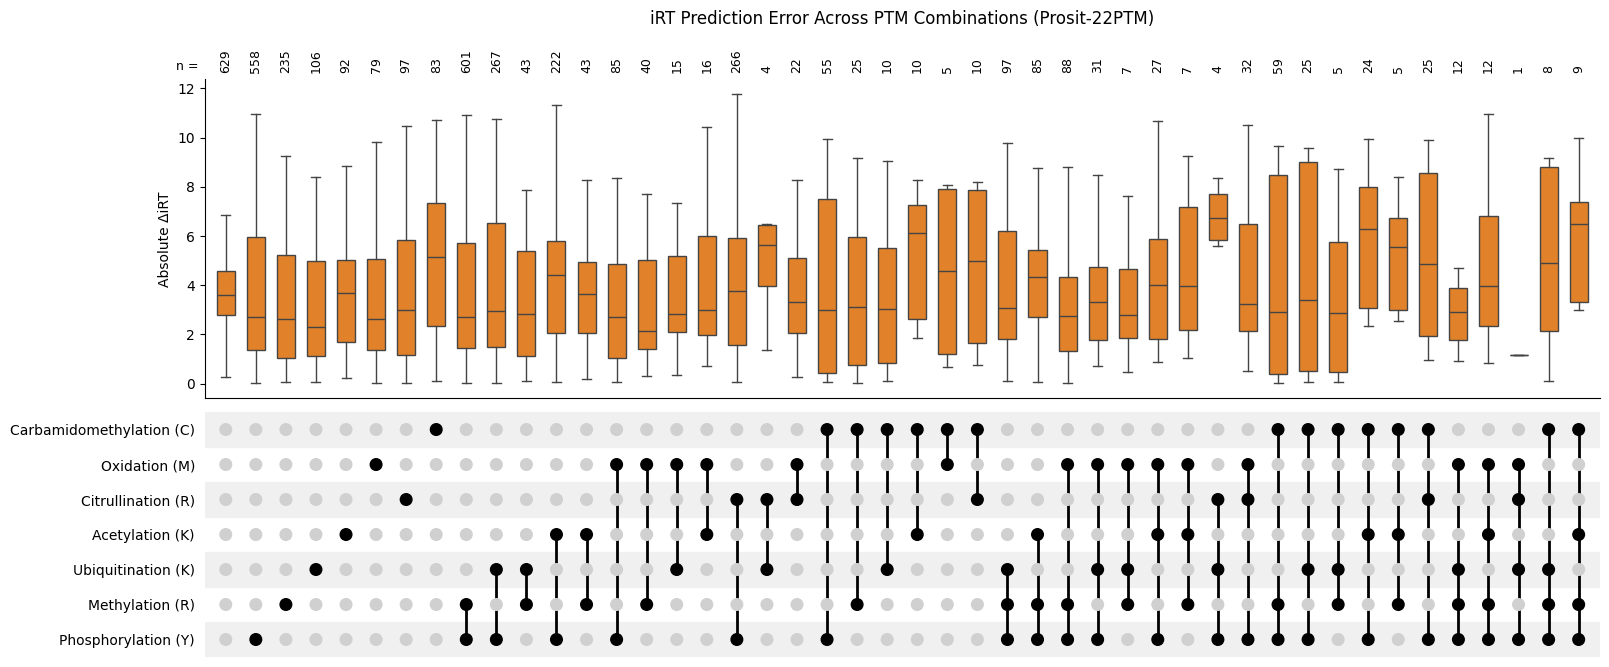

,modification_combination,n_peptides,Q1 (iRT),median (iRT),Q3 (iRT)
0,unmodified,629,2.79,3.61,4.58
1,Phosphorylation,558,1.34,2.72,5.95
2,Methylation,235,1.03,2.63,5.23
3,Ubiquitination,106,1.11,2.31,4.99
4,Acetylation,92,1.71,3.66,5.01
5,Oxidation,79,1.35,2.61,5.06
6,Citrullination,97,1.18,3.00,5.83
7,Carbamidomethylation,83,2.33,5.16,7.32
8,Phosphorylation + Methylation,601,1.43,2.72,5.72
9,Phosphorylation + Ubiquitination,267,1.50,2.94,6.55


In [3]:
pep = pd.read_parquet(fetch('Wilhelm_SourceData_ED_Fig9a.parquet'))
summ = table('ED_Fig9a_summary')
order = summ['modification_combination'].tolist()
mods = [c for c in summ.columns if c.endswith(')') and c.split(' (')[0] in
        ('Phosphorylation', 'Methylation', 'Ubiquitination', 'Acetylation', 'Citrullination', 'Oxidation', 'Carbamidomethylation')]
rows_top_to_bottom = mods[::-1]  # Carbamidomethylation on top, Phosphorylation at the bottom
groups = [pep.loc[pep['modification_combination'] == c, 'prosit_irt_diff (iRT)'].values for c in order]

fig, (ax, axm) = plt.subplots(2, 1, figsize=(18, 7.5), sharex=True, gridspec_kw={'height_ratios': [1.3, 1], 'hspace': 0.05})
x = np.arange(len(order))
ax.boxplot(groups, positions=x, widths=0.6, showfliers=False, whis=1.5, patch_artist=True,
           boxprops=dict(facecolor='#E1822B', edgecolor='#444444'), medianprops=dict(color='#444444'),
           whiskerprops=dict(color='#444444'), capprops=dict(color='#444444'))
ymax = ax.get_ylim()[1]
for xi, g in zip(x, groups):
    ax.text(xi, ymax * 1.02, str(len(g)), rotation=90, ha='center', va='bottom', fontsize=9)
ax.text(-0.9, ymax * 1.02, 'n =', ha='right', va='bottom', fontsize=9)
ax.set_ylabel('Absolute ΔiRT')
ax.set_title('iRT Prediction Error Across PTM Combinations (Prosit-22PTM)', pad=40)
ax.spines[['top', 'right']].set_visible(False)

for r, m in enumerate(rows_top_to_bottom):
    yy = len(rows_top_to_bottom) - 1 - r
    if r % 2 == 0:
        axm.axhspan(yy - 0.5, yy + 0.5, color='#f0f0f0', zorder=0)
    member = summ[m].astype(bool).values
    axm.scatter(x, np.full(len(x), yy), s=70, c=np.where(member, 'black', '#d0d0d0'), zorder=2)
for xi in x:
    ys = [len(rows_top_to_bottom) - 1 - r for r, m in enumerate(rows_top_to_bottom) if summ.loc[xi, m]]
    if len(ys) > 1:
        axm.plot([xi, xi], [min(ys), max(ys)], color='black', lw=2, zorder=1)
axm.set_yticks(range(len(rows_top_to_bottom)), [m for m in rows_top_to_bottom][::-1])
axm.set_ylim(-0.5, len(rows_top_to_bottom) - 0.5)
axm.set_xticks([])
axm.set_xlim(-0.7, len(order) - 0.3)
for s in axm.spines.values():
    s.set_visible(False)
axm.tick_params(left=False)
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'ED_Fig9a.{ext}', dpi=300, bbox_inches='tight')
plt.show()
summ[['modification_combination', 'n_peptides', 'Q1 (iRT)', 'median (iRT)', 'Q3 (iRT)']].round(2)

## b — iRT prediction error, DeepLC vs Prosit-22PTM

Absolute ΔiRT per PTM combination, DeepLC (x) vs Prosit-22PTM (y), coloured by the number of different PTM types in the peptide; dashed line = diagonal.

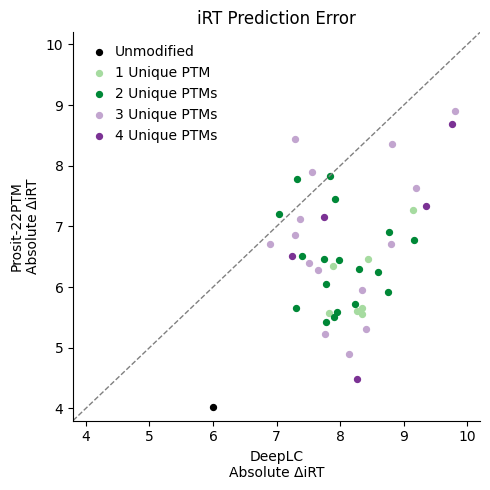

,modification_combination,n_unique_PTMs,DeepLC_abs_delta_iRT (iRT),Prosit-22PTM_abs_delta_iRT (iRT)
0,unmodified,0,6.000,4.019
1,Phosphorylation,1,8.432,6.462
2,Methylation,1,8.347,5.655
3,Ubiquitination,1,8.345,5.556
4,Acetylation,1,7.818,5.570
5,Oxidation,1,8.264,5.609
6,Citrullination,1,7.882,6.350
7,Carbamidomethylation,1,9.147,7.268
8,Phosphorylation + Methylation,2,8.603,6.244
9,Phosphorylation + Ubiquitination,2,8.776,6.912


In [4]:
b = table('ED_Fig9b')
xc, yc = 'DeepLC_abs_delta_iRT (iRT)', 'Prosit-22PTM_abs_delta_iRT (iRT)'
fig, ax = plt.subplots(figsize=(5, 5))
for k, sub in b.groupby('n_unique_PTMs'):
    ax.scatter(sub[xc], sub[yc], s=18, color=K_COLORS[k], label=K_LABELS[k])
lim = [3.8, 10.2]
ax.plot(lim, lim, ls='--', color='grey', lw=1)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('DeepLC\nAbsolute ΔiRT')
ax.set_ylabel('Prosit-22PTM\nAbsolute ΔiRT')
ax.set_title('iRT Prediction Error')
ax.legend(frameon=False, loc='upper left', handletextpad=0.1)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'ED_Fig9b.{ext}', dpi=300, bbox_inches='tight')
plt.show()
b

## c — fragment ion intensity prediction accuracy, AlphaPeptDeep vs Prosit-22PTM

Median spectral angle of HCD spectra per PTM combination, AlphaPeptDeep (x) vs Prosit-22PTM (y), coloured by the number of different PTM types in the peptide; dashed line = diagonal.

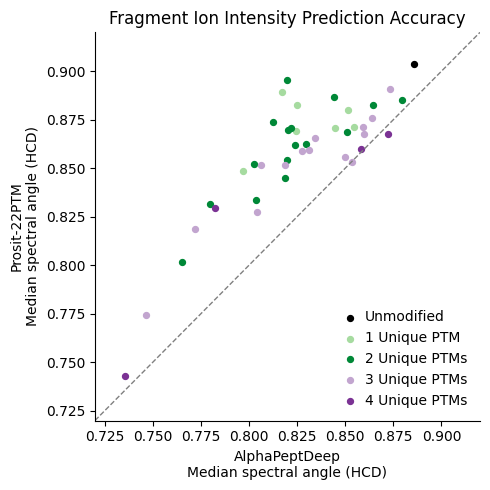

,modification_combination,n_unique_PTMs,AlphaPeptDeep_median_spectral_angle_HCD (0-1),Prosit-22PTM_median_spectral_angle_HCD (0-1)
0,unmodified,0,0.8855,0.9039
1,Phosphorylation,1,0.7968,0.8488
2,Methylation,1,0.8245,0.8694
3,Ubiquitination,1,0.8516,0.8802
4,Acetylation,1,0.8249,0.8826
5,Oxidation,1,0.8546,0.8713
6,Citrullination,1,0.8174,0.8892
7,Carbamidomethylation,1,0.8448,0.8706
8,Phosphorylation + Methylation,2,0.7798,0.8316
9,Phosphorylation + Ubiquitination,2,0.8024,0.8524


In [5]:
c = table('ED_Fig9c')
xc, yc = 'AlphaPeptDeep_median_spectral_angle_HCD (0-1)', 'Prosit-22PTM_median_spectral_angle_HCD (0-1)'
fig, ax = plt.subplots(figsize=(5, 5))
for k, sub in c.groupby('n_unique_PTMs'):
    ax.scatter(sub[xc], sub[yc], s=18, color=K_COLORS[k], label=K_LABELS[k])
lo, hi = 0.72, 0.92
ax.plot([lo, hi], [lo, hi], ls='--', color='grey', lw=1)
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel('AlphaPeptDeep\nMedian spectral angle (HCD)')
ax.set_ylabel('Prosit-22PTM\nMedian spectral angle (HCD)')
ax.set_title('Fragment Ion Intensity Prediction Accuracy')
ax.legend(frameon=False, loc='lower right', handletextpad=0.1)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'ED_Fig9c.{ext}', dpi=300, bbox_inches='tight')
plt.show()
c